In [21]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import momepy as mp
import networkx as nx
import numpy as np
import pandas as pd

In [22]:
def compute_gini(gdf_edges, gdf_arr):
    """Compute the Gini coefficient of distribution of edges on polygons, normalized by their area."""
    gdf_sjoin = gdf_arr.sjoin(gdf_edges)
    gdf_sjoin["eff_length"] = gdf_sjoin["length"] / gdf_sjoin["index_right"].map(
        gdf_sjoin["index_right"].value_counts()
    )
    gdf_sjoin = gdf_sjoin.dissolve(
        by="arrondissement", aggfunc={"eff_length": "sum", "area": "first"}
    )
    arr_vals = gdf_sjoin["eff_length"] / gdf_sjoin["area"]
    return gini(arr_vals)


# Function from https://github.com/oliviaguest/gini
def gini(array):
    """Calculate the Gini coefficient of a numpy array."""
    array = np.sort(array)  # values must be sorted
    index = np.arange(1, array.shape[0] + 1)  # index per array element
    n = array.shape[0]  # number of array elements
    return (np.sum((2 * index - n - 1) * array)) / (
        n * np.sum(array)
    )  # Gini coefficient


def init_gdf(gdf_edges, end_folder):
    gdf = gdf_edges.copy()
    if end_folder == "2021":
        gdf["built"] = gdf["built_in"].apply(lambda x: 1 if x == "2021-01-01" else 0)
    elif end_folder == "2026":
        gdf["built"] = gdf["built_in"].apply(lambda x: 1 if x != "No" else 0)
    elif end_folder == "Nothing":
        G = mp.gdf_to_nx(gdf, integer_labels=False, preserve_index=True)
        closeness = nx.closeness_centrality(G, distance="length")
        edge_closeness = {
            edge: (closeness[edge[0]] + closeness[edge[1]]) / 2
            for edge in G.edges
            if (
                (G.edges[edge]["highway"] == "primary")
                & (G.edges[edge]["level"] == "primary")
                & (G.edges[edge]["built_in"] == "2021-01-01")
            )
        }
        choice = max(edge_closeness, key=edge_closeness.get)
        gdf["built"] = gdf.apply(
            lambda df: (
                1
                if (
                    ((df["from"] == str(choice[0])) & (df["to"] == str(choice[1])))
                    or ((df["to"] == str(choice[0])) & (df["from"] == str(choice[1])))
                )
                else 0
            ),
            axis=1,
        )
    return gdf

In [23]:
gdf_bikenet = gpd.read_file("../data/processed/bikenet_edges.gpkg")

In [24]:
gdf_arr = gpd.read_file("../data/processed/paris_arr_pop.gpkg")
gdf_arr_buff = gdf_arr.to_crs(gdf_bikenet.crs)
gdf_arr_buff.geometry = gdf_arr_buff.buffer(50)

In [25]:
gdf_sjoin = gdf_arr_buff.sjoin(gdf_bikenet)
gdf_sjoin["eff_length"] = gdf_sjoin["length"] / gdf_sjoin["index_right"].map(
    gdf_sjoin["index_right"].value_counts()
)
gdf_sjoin = gdf_sjoin.dissolve(
    by="arrondissement", aggfunc={"eff_length": "sum", "area": "first"}
)
gdf_sjoin["lanes_per_kms"] = (gdf_sjoin["eff_length"] / 10**3) / gdf_sjoin["area"]

<Axes: >

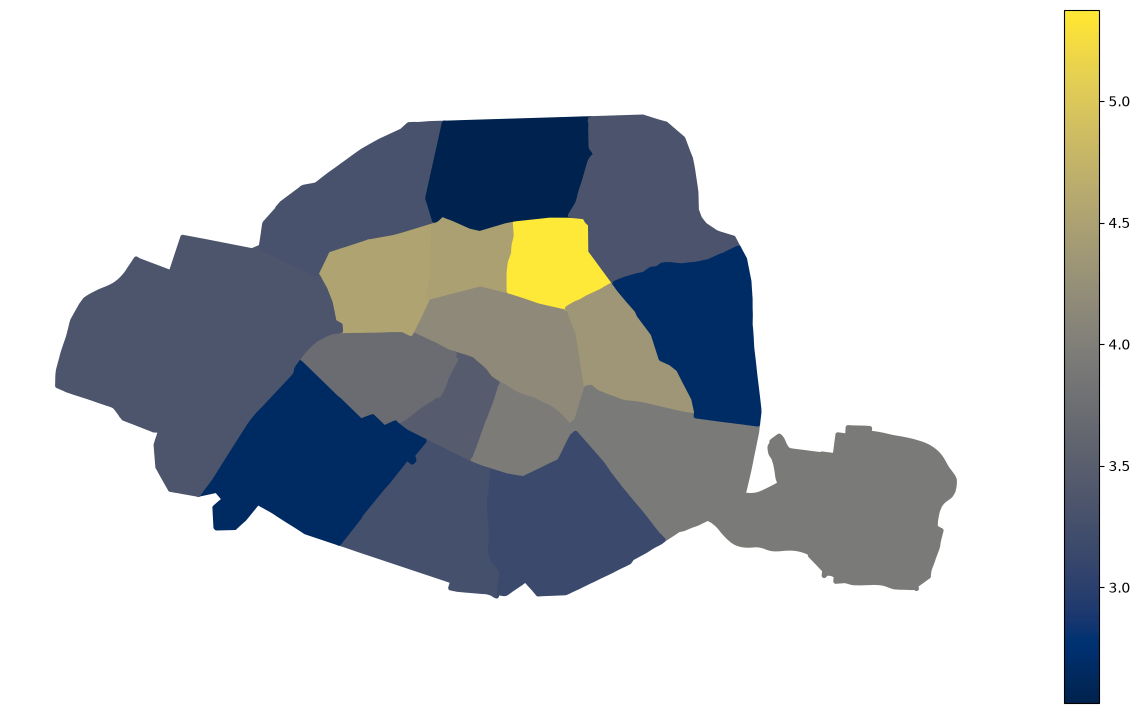

In [26]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_axis_off()
gdf_sjoin.plot(ax=ax, column="lanes_per_kms", legend=True, cmap="cividis")

Text(0, 0.5, 'Lane kilometer per kilometer square')

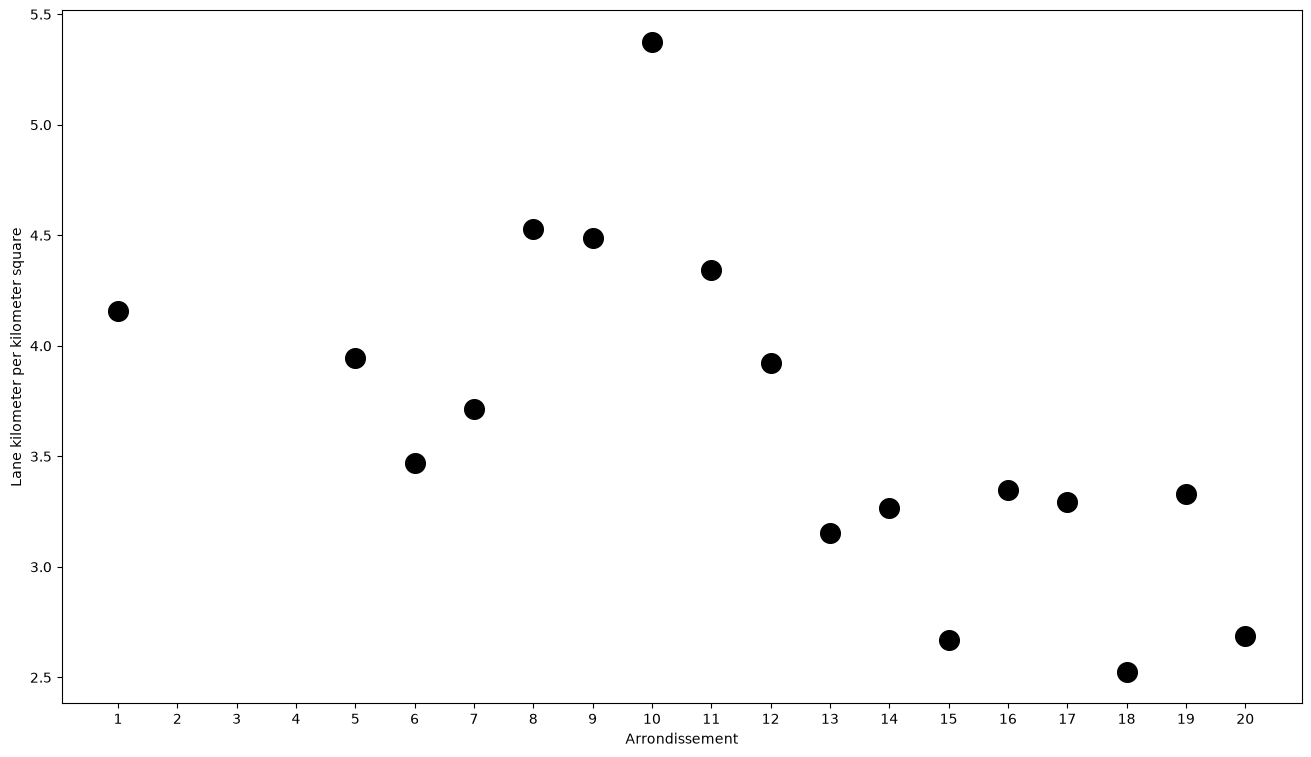

In [27]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xticks(range(1, 21))
ax.scatter(gdf_sjoin.index, gdf_sjoin["lanes_per_kms"], color="black", s=200)
ax.set_xlabel("Arrondissement")
ax.set_ylabel("Lane kilometer per kilometer square")

In [28]:
gdf_sjoin["rep"] = gdf_sjoin.geometry.centroid

<Axes: >

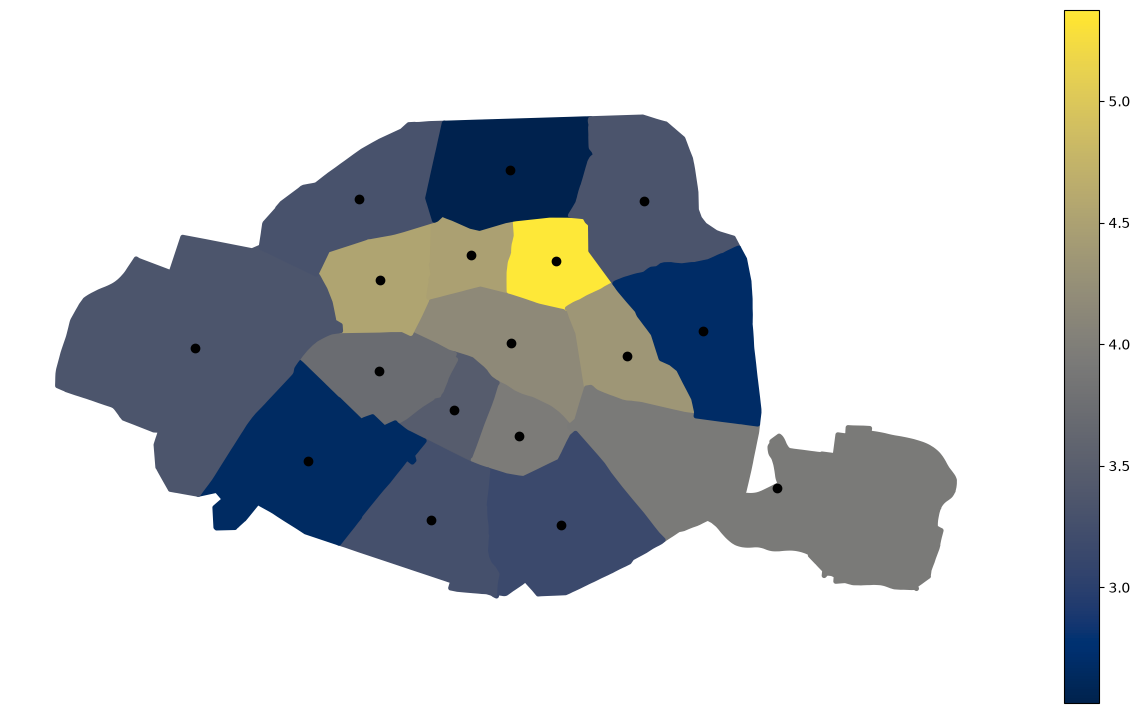

In [29]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_axis_off()
gdf_sjoin.plot(ax=ax, column="lanes_per_kms", legend=True, cmap="cividis")
gdf_sjoin["rep"].plot(ax=ax, color="black")

In [30]:
gdf_sjoin["dist_to_center"] = gdf_sjoin["rep"].distance(gdf_sjoin.loc[1, "rep"]) / 10**3

Text(0, 0.5, 'Lane kilometer per kilometer square')

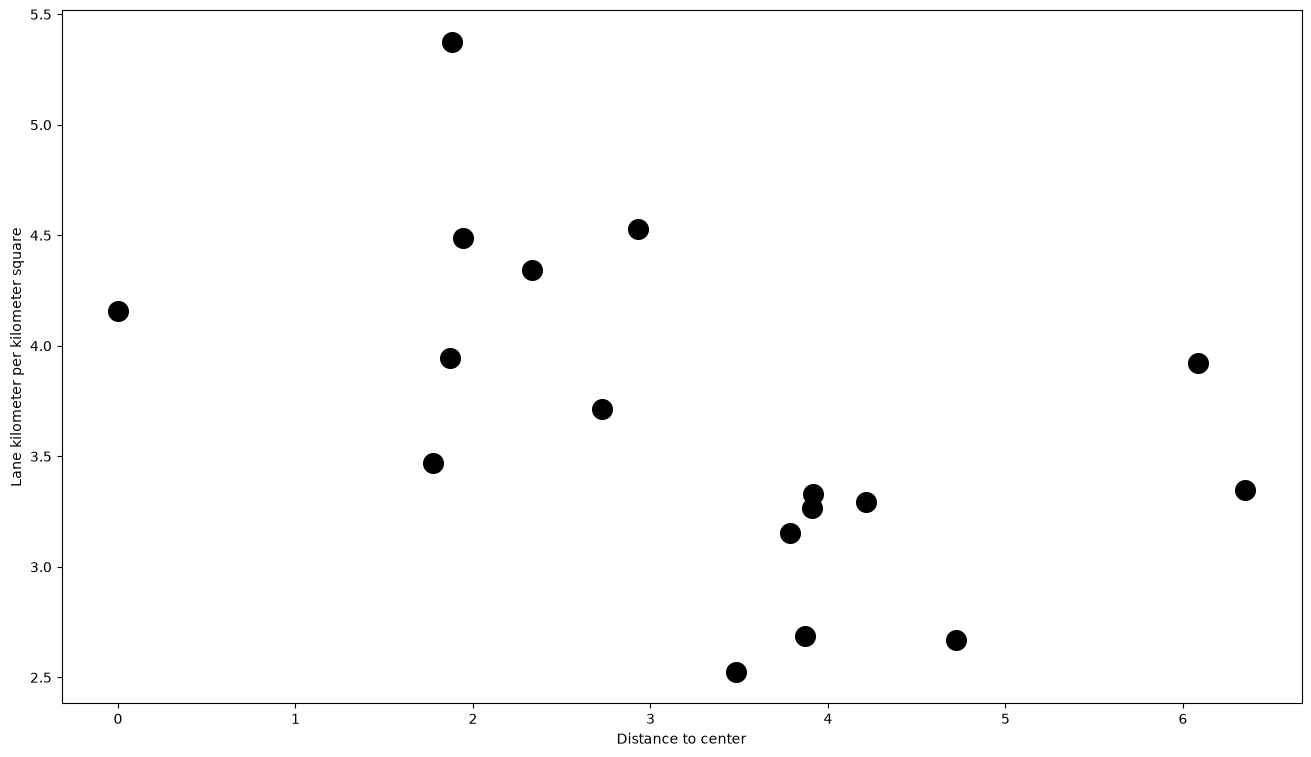

In [31]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.scatter(
    gdf_sjoin["dist_to_center"], gdf_sjoin["lanes_per_kms"], color="black", s=200
)
ax.set_xlabel("Distance to center")
ax.set_ylabel("Lane kilometer per kilometer square")

In [32]:
TIMESTAMPS = [
    "2021-01-01",
    "2023-05-17",
    "2023-10-01",
    "2024-01-15",
    "2024-04-04",
    "2024-08-22",
    "2024-12-22",
    "2025-06-02",
    "2026-01-28",
    "No",
]

In [33]:
real_ginis = []
for i in range(len(TIMESTAMPS)):
    gdf_edges = gdf_bikenet[gdf_bikenet["built_in"].isin(TIMESTAMPS[: i + 1])]
    real_ginis.append(compute_gini(gdf_edges, gdf_arr_buff))

In [34]:
real_met = pd.read_json("../data/processed/2021/bs_400_real/metrics_growth.json")

In [35]:
gdf_end = init_gdf(gdf_bikenet, "2021")

In [36]:
def compute_gini_order(gdf_edges, gdf_arr, order_growth):
    gdf_end = gdf_edges.copy()
    gdf_arr_cop = gdf_arr.copy()
    gdf_arr_cop["lkm"] = 0.0
    gdf_arr_cop["lkmpkms"] = 0.0
    # Make order growth readable
    order_growth = [(tuple(val[0]), tuple(val[1]), val[2]) for val in order_growth]
    # Swap u and v to find all edges
    order_growth_rev = [(tuple(val[1]), tuple(val[0]), val[2]) for val in order_growth]
    order_dict = {val: idx for idx, val in enumerate(order_growth)}
    order_dict_rev = {val: idx for idx, val in enumerate(order_growth_rev)}
    # Transfrom strings into tuple of float
    gdf_end["from"] = gdf_end["from"].apply(
        lambda x: (float(x.split(",")[0][1:]), float(x.split(",")[1][1:-1]))
    )
    gdf_end["to"] = gdf_end["to"].apply(
        lambda x: (float(x.split(",")[0][1:]), float(x.split(",")[1][1:-1]))
    )
    gdf_end["key"] = gdf_end.apply(lambda df: (df["from"], df["to"], 0), axis=1)
    # Find order of growth for list of edges
    gdf_end["order"] = gdf_end["key"].map(order_dict)
    gdf_end["order_rev"] = gdf_end["key"].map(order_dict_rev)
    gdf_end["order_comb"] = gdf_end["order"].fillna(gdf_end["order_rev"])
    gdf_end["order_comb"] = gdf_end["order_comb"].fillna(-1).map(int)
    gdf_end = gdf_end.sort_values(by="order_comb")
    # Find on what arrondissement each edge is
    gdf_sjoin_other = gdf_bikenet.sjoin(gdf_arr_buff)
    gdf_end["in_arrs"] = gdf_sjoin_other.groupby(by=gdf_sjoin_other.index)[
        "arrondissement"
    ].apply(list)
    gdf_end["eff_length"] = gdf_end["length"] / gdf_end["in_arrs"].map(len)
    # Remove useless columns
    gdf_end = gdf_end[
        ["level", "order_comb", "length", "eff_length", "in_arrs", "geometry"]
    ]
    # Initialize with edges built in the beginning
    gdf_built = gdf_end[gdf_end["order_comb"] == -1]
    # Add edges to the corresponding arrs
    for row in gdf_built.itertuples(index=False):
        gdf_arr_cop.loc[gdf_arr_cop["arrondissement"].isin(row.in_arrs), "lkm"] += (
            row.eff_length / 10**3
        )
    gdf_arr_cop["lkmpkms"] = gdf_arr_cop["lkm"] / gdf_arr_cop["area"]
    gini_vals = [gini(gdf_arr_cop["lkmpkms"])]
    for row in gdf_end[gdf_end["order_comb"] > -1].itertuples(index=False):
        gdf_arr_cop.loc[gdf_arr_cop["arrondissement"].isin(row.in_arrs), "lkm"] += (
            row.eff_length / 10**3
        )
        gdf_arr_cop.loc[gdf_arr_cop["arrondissement"].isin(row.in_arrs), "lkmpkms"] = (
            gdf_arr_cop.loc[gdf_arr_cop["arrondissement"].isin(row.in_arrs), "lkm"]
            / gdf_arr_cop.loc[gdf_arr_cop["arrondissement"].isin(row.in_arrs), "area"]
        )
        gini_vals.append(gini(gdf_arr_cop["lkmpkms"].values))
    return gini_vals

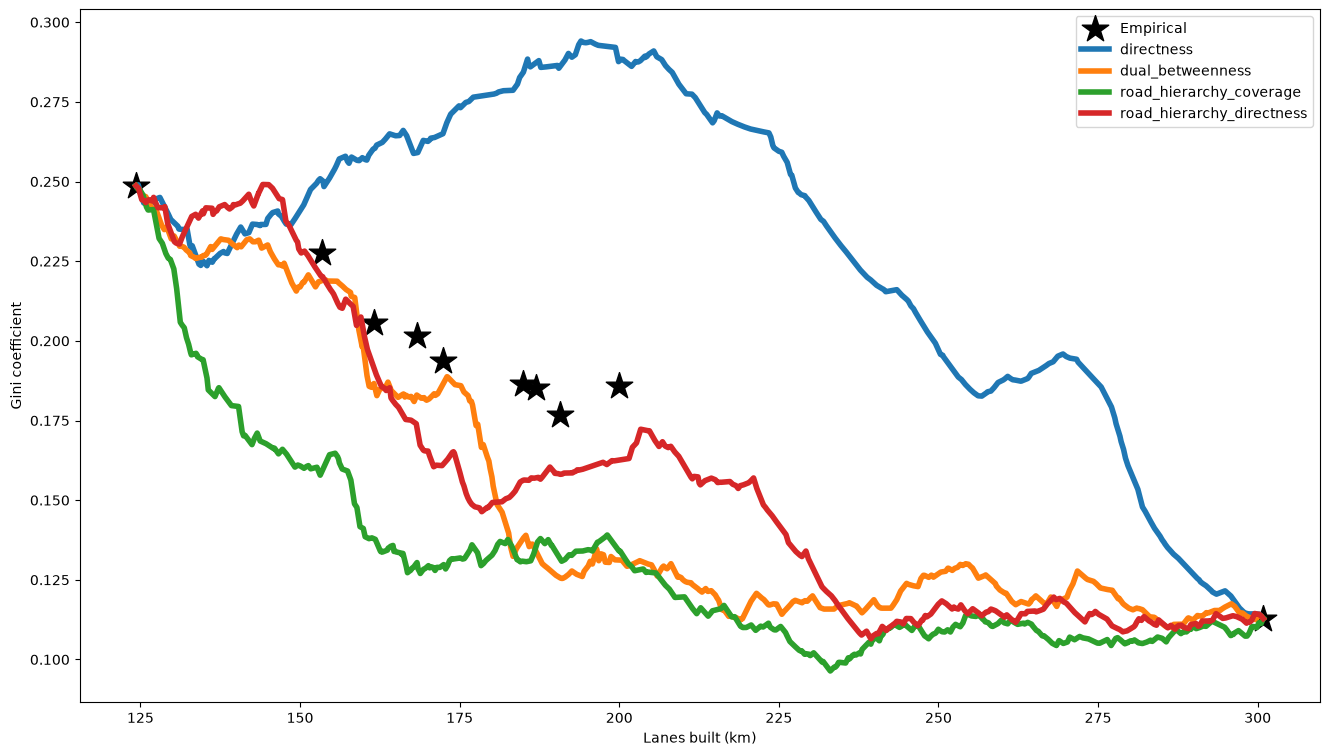

In [38]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.scatter(
    real_met["xx"] / 10**3,
    real_ginis,
    color="black",
    marker="*",
    s=400,
    label="Empirical",
)
for met in [
    "directness",
    "dual_betweenness",
    "road_hierarchy_coverage",
    "road_hierarchy_directness",
]:
    with open(f"../data/processed/2021/bs_400_{met}/" + "order_growth.json") as f:
        order_growth = json.load(f)
    with open(f"../data/processed/2021/bs_400_{met}/" + "metrics_growth.json") as f:
        met_dict = json.load(f)
    ginis = compute_gini_order(gdf_end, gdf_arr_buff, order_growth)
    ax.plot(
        np.array(met_dict["xx"]) / 10**3,
        ginis,
        label=met,
        linewidth=4,
    )
ax.set_ylabel("Gini coefficient")
ax.set_xlabel("Lanes built (km)")
ax.legend()